In [1]:
#libraries
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

from itertools import product

## If you have an error here saying ydata_profiling is not available
## Run the instructions above
## IF you are still unable to install `ydata-profiling` through this method, 
## Comment out the line below importing ProfileReport
from ydata_profiling import ProfileReport

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

# Setting seaborn style
MAIN_COLOR = "#4A90C2"
colors = ["#2F5D7C", "#4A90C2", "#F6CF6B", "#FAA85E", "#F26B4E"]
sns.set_theme(style="ticks", palette=colors)

/var/folders/95/1xf01h296vjbznnd0l4gq4300000gn/T/ipykernel_46161/3984301044.py:16: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [2]:
df_raw = pd.read_csv("../data/acdc_dataset.csv", sep=";", index_col="member_id")
df_raw.head()


,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [3]:
df_raw.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In [5]:
df_raw['membership_start'] = pd.to_datetime(df_raw["membership_start"], format='mixed')
df_raw['membership_end'] = pd.to_datetime(df_raw["membership_end"], format='mixed')
df_raw['last_badge_swipe'] = pd.to_datetime(df_raw["last_badge_swipe"], format='mixed')

In [6]:
df_raw["lifetime_value"] = (
    df_raw["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

In [7]:
df_raw.dtypes

age                                   float64
gender                                 object
industry                               object
country                                object
is_team_account                          bool
n_colleagues_on_account                 int64
plan_tier                              object
plan_days_per_week                      int64
membership_start               datetime64[ns]
membership_end                 datetime64[ns]
last_badge_swipe               datetime64[ns]
days_since_last_visit                   int64
total_visits                            int64
avg_weekly_visits                     float64
entitled_visits_last_period           float64
actual_visits_last_period               int64
meeting_room_hours                    float64
event_space_hours                     float64
guest_passes_issued                   float64
uses_meeting_rooms                       bool
uses_event_space                         bool
uses_guest_passes                 

# Descriptive statistics for metric and non metric valiables

In [8]:
df_raw.isna().sum()[lambda s: s > 0]

age                     558
gender                  530
country                 430
plan_tier               105
meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
dtype: int64

In [9]:
df_raw.uses_print = df_raw.uses_print.astype("boolean")
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_print,15465,2,False,10469
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


In [10]:
df_raw.describe(include="object").T
#plan tier should only have 5 unique values
#gender shou have 3: Female, Male, Other

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182


In [11]:
#Turning object values to lower case
cols_object = df_raw.select_dtypes(include="object").columns
df_raw[cols_object] = df_raw[cols_object].apply(lambda s: s.str.lower())

print(f"Gender unique values: {df_raw["gender"].unique()}")
print(f"Country unique values: {df_raw["country"].unique()}")
print(f"Plan tier unique values: {df_raw["plan_tier"].unique()}")
print(f"Industry unique values: {df_raw["industry"].unique()}")

Gender unique values: ['female' 'male' 'f' 'other' nan ' female' 'm' ' male' ' other' 'o']
Country unique values: ['portugal' 'de' 'united kingdom' 'spain' 'germany' 'netherlands' 'france'
 'pt' 'other (europe)' 'portucal' nan 'uk' 'ireland' 'ie' 'portugal '
 'deutschland' 'u.k.' 'gb' 'es' 'nl' 'españa' 'espana' 'the netherlands'
 'fr' 'holland']
Plan tier unique values: ['flex' 'hot_desk' 'dedicated_desk' 'full_time' 'private_office'
 'hot desk' 'dedicateddesk' nan 'hotdesk' 'fulltime' 'privateoffice'
 'full time' 'dedicated desk' 'private office']
Industry unique values: ['information technology' 'education' 'legal' 'health' 'unknown' 'other'
 'consulting' 'design & creative' 'finance' 'marketing & pr'
 'marketing and pr' 'real estate' 'marketing/pr' 'design/creative'
 'realestate' 'it' 'tech' 'design and creative' 'real-estate']


In [12]:
#Replacing gender values
df_raw["gender"] = df_raw["gender"].replace([" female", "f"], "female")
df_raw["gender"] = df_raw["gender"].replace([" male", "m"], "male")
df_raw["gender"] = df_raw["gender"].replace([" other", "o"], "other")

#Replacing country values
df_raw["country"] = df_raw["country"].replace({
    "portucal":"portugal", "portugal ":"portugal", "pt":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom", "gb":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "nl":"netherlands", "the netherlands":"netherlands", "holland":"netherlands",
    "fr":"france",
    "ie":"ireland"})

#Replacing Plan tier values
df_raw["plan_tier"] = df_raw["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df_raw["plan_tier"] = df_raw["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df_raw["plan_tier"] = df_raw["plan_tier"].replace(["fulltime", "full time"], "full_time")
df_raw["plan_tier"] = df_raw["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df_raw["industry"] = df_raw["industry"].replace(["it", "tech"], "information technology")
df_raw["industry"] = df_raw["industry"].replace(["design & creative", "design/creative"], "design and creative")
df_raw["industry"] = df_raw["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df_raw["industry"] = df_raw["industry"].replace(["realestate", "real-estate"], "real estate")

df_raw.describe(include="object").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,8,portugal,10508
plan_tier,15360,5,flex,5453


In [13]:
df_raw.duplicated().sum()
#269 duplicated rows

np.int64(295)

In [14]:
df_nodups = df_raw.drop_duplicates()
df_nodups.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
age,14626.0,34.87,1.0,29.0,34.0,40.0,149.0,10.41
n_colleagues_on_account,15170.0,0.54,-1.0,0.0,0.0,1.0,9.0,1.18
plan_days_per_week,15170.0,3.39,0.0,2.0,3.0,5.0,9.0,1.46
membership_start,15170,2022-03-15 23:58:45.959129600,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-07 00:00:00,2022-11-05 00:00:00,2023-12-30 00:00:00,NaN
membership_end,15170,2009-05-22 16:11:21.555702016,1970-01-01 00:00:00,1970-01-01 00:00:00,2022-08-22 00:00:00,2023-06-10 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15170,2023-02-14 01:24:46.038233344,2020-09-06 00:00:00,2022-08-13 00:00:00,2023-05-06 00:00:00,2023-10-16 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15170.0,117.07,-956.0,4.0,13.0,55.0,1212.0,275.45
total_visits,15170.0,110.42,-112.0,8.0,34.0,132.0,6530.0,183.28
avg_weekly_visits,15170.0,1.77,0.0,0.71,1.42,2.41,47.4,1.93
entitled_visits_last_period,15170.0,27.52,0.0,17.39,26.09,43.48,78.27,13.48


In [15]:
df_nodups.loc[df_nodups["days_since_last_visit"] < 0, ["days_since_last_visit", "membership_start", "membership_end", "last_badge_swipe"]]

,days_since_last_visit,membership_start,membership_end,last_badge_swipe
member_id,,,,
CW000001,-17,2021-08-01,2023-03-06,2023-03-23
CW000480,-240,2021-09-10,2021-09-15,2022-05-13
CW000498,-643,2022-05-10,2022-02-10,2023-11-15
CW000541,-102,2022-01-06,2022-08-30,2022-12-10
CW000788,-101,2021-12-20,1970-01-01,2024-04-11
CW001018,-734,2022-03-09,2021-12-17,2023-12-21
CW001384,-38,2021-01-07,2023-11-20,2023-12-28
CW001474,-88,2022-05-23,1970-01-01,2024-03-29
CW001483,-103,2021-07-13,1970-01-01,2024-04-13


In [16]:
non_metric_features = ['gender', 'country', 'industry', 'plan_tier', 'is_team_account',
 'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
 'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes',
 'uses_storage', 'uses_bike_locker']

metric_features = df_nodups.columns.drop(non_metric_features).to_list()
metric_features

['age',
 'n_colleagues_on_account',
 'plan_days_per_week',
 'membership_start',
 'membership_end',
 'last_badge_swipe',
 'days_since_last_visit',
 'total_visits',
 'avg_weekly_visits',
 'entitled_visits_last_period',
 'actual_visits_last_period',
 'meeting_room_hours',
 'event_space_hours',
 'guest_passes_issued',
 'n_renewals',
 'lifetime_value']

# Visualizations for metric variables

- Histograms/Box plots for each variable
- Explore relationships between varibales
- Correlation between variables (heatmap)

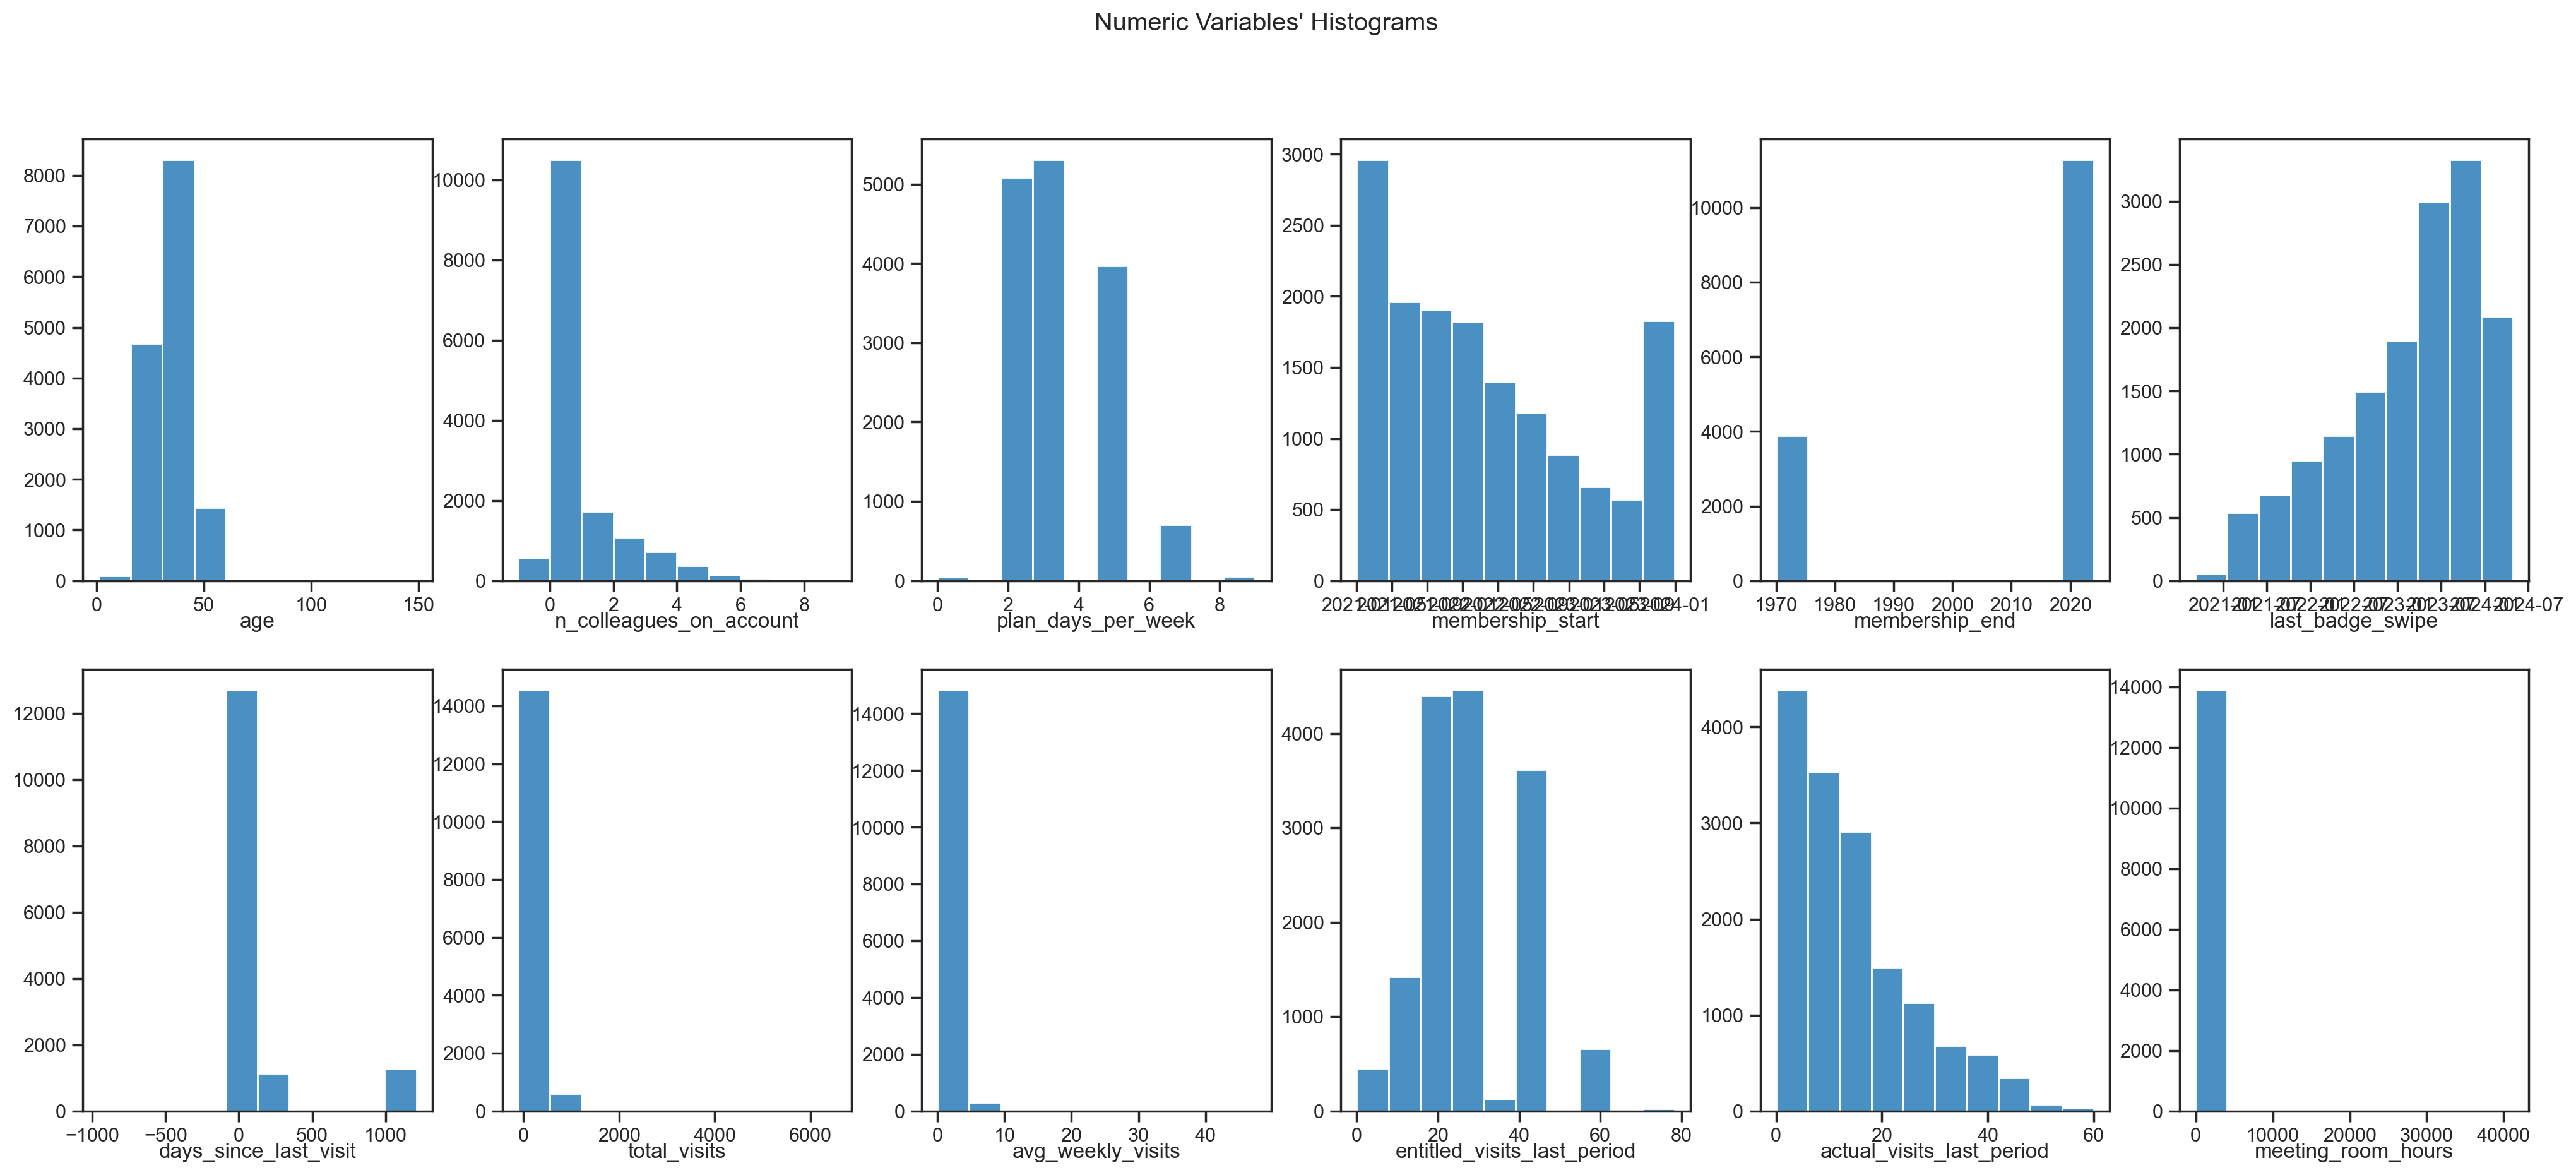

In [17]:
# Plot ALL Numeric Variables' Histograms in one figure

sp_rows = 2
sp_cols = 6


# Prepare figure. Create individual axes where each histogram will be placed
fig, axes = plt.subplots(sp_rows, 
                         sp_cols, 
                         figsize=(25, 10))

# Plot data
# Iterate across axes objects and associate each histogram (hint: use the ax.hist() instead of plt.hist()):
for ax, feat in zip(axes.flatten(), metric_features):
    ax.hist(df_nodups[feat], color=MAIN_COLOR, edgecolor="white")
    ax.set_title(feat, y=-0.13)
    
# Layout
# Add a centered title to the figure:
title = "Numeric Variables' Histograms"

plt.suptitle(title)

if not os.path.exists(os.path.join('..', 'figures', 'eda')):
    # if the exp_analysis directory is not present then create it first
    os.makedirs(os.path.join('..', 'figures', 'eda'))
    
plt.savefig(os.path.join('..', 'figures', 'eda', 'numeric_variables_histograms.png'), dpi=200)

plt.show()

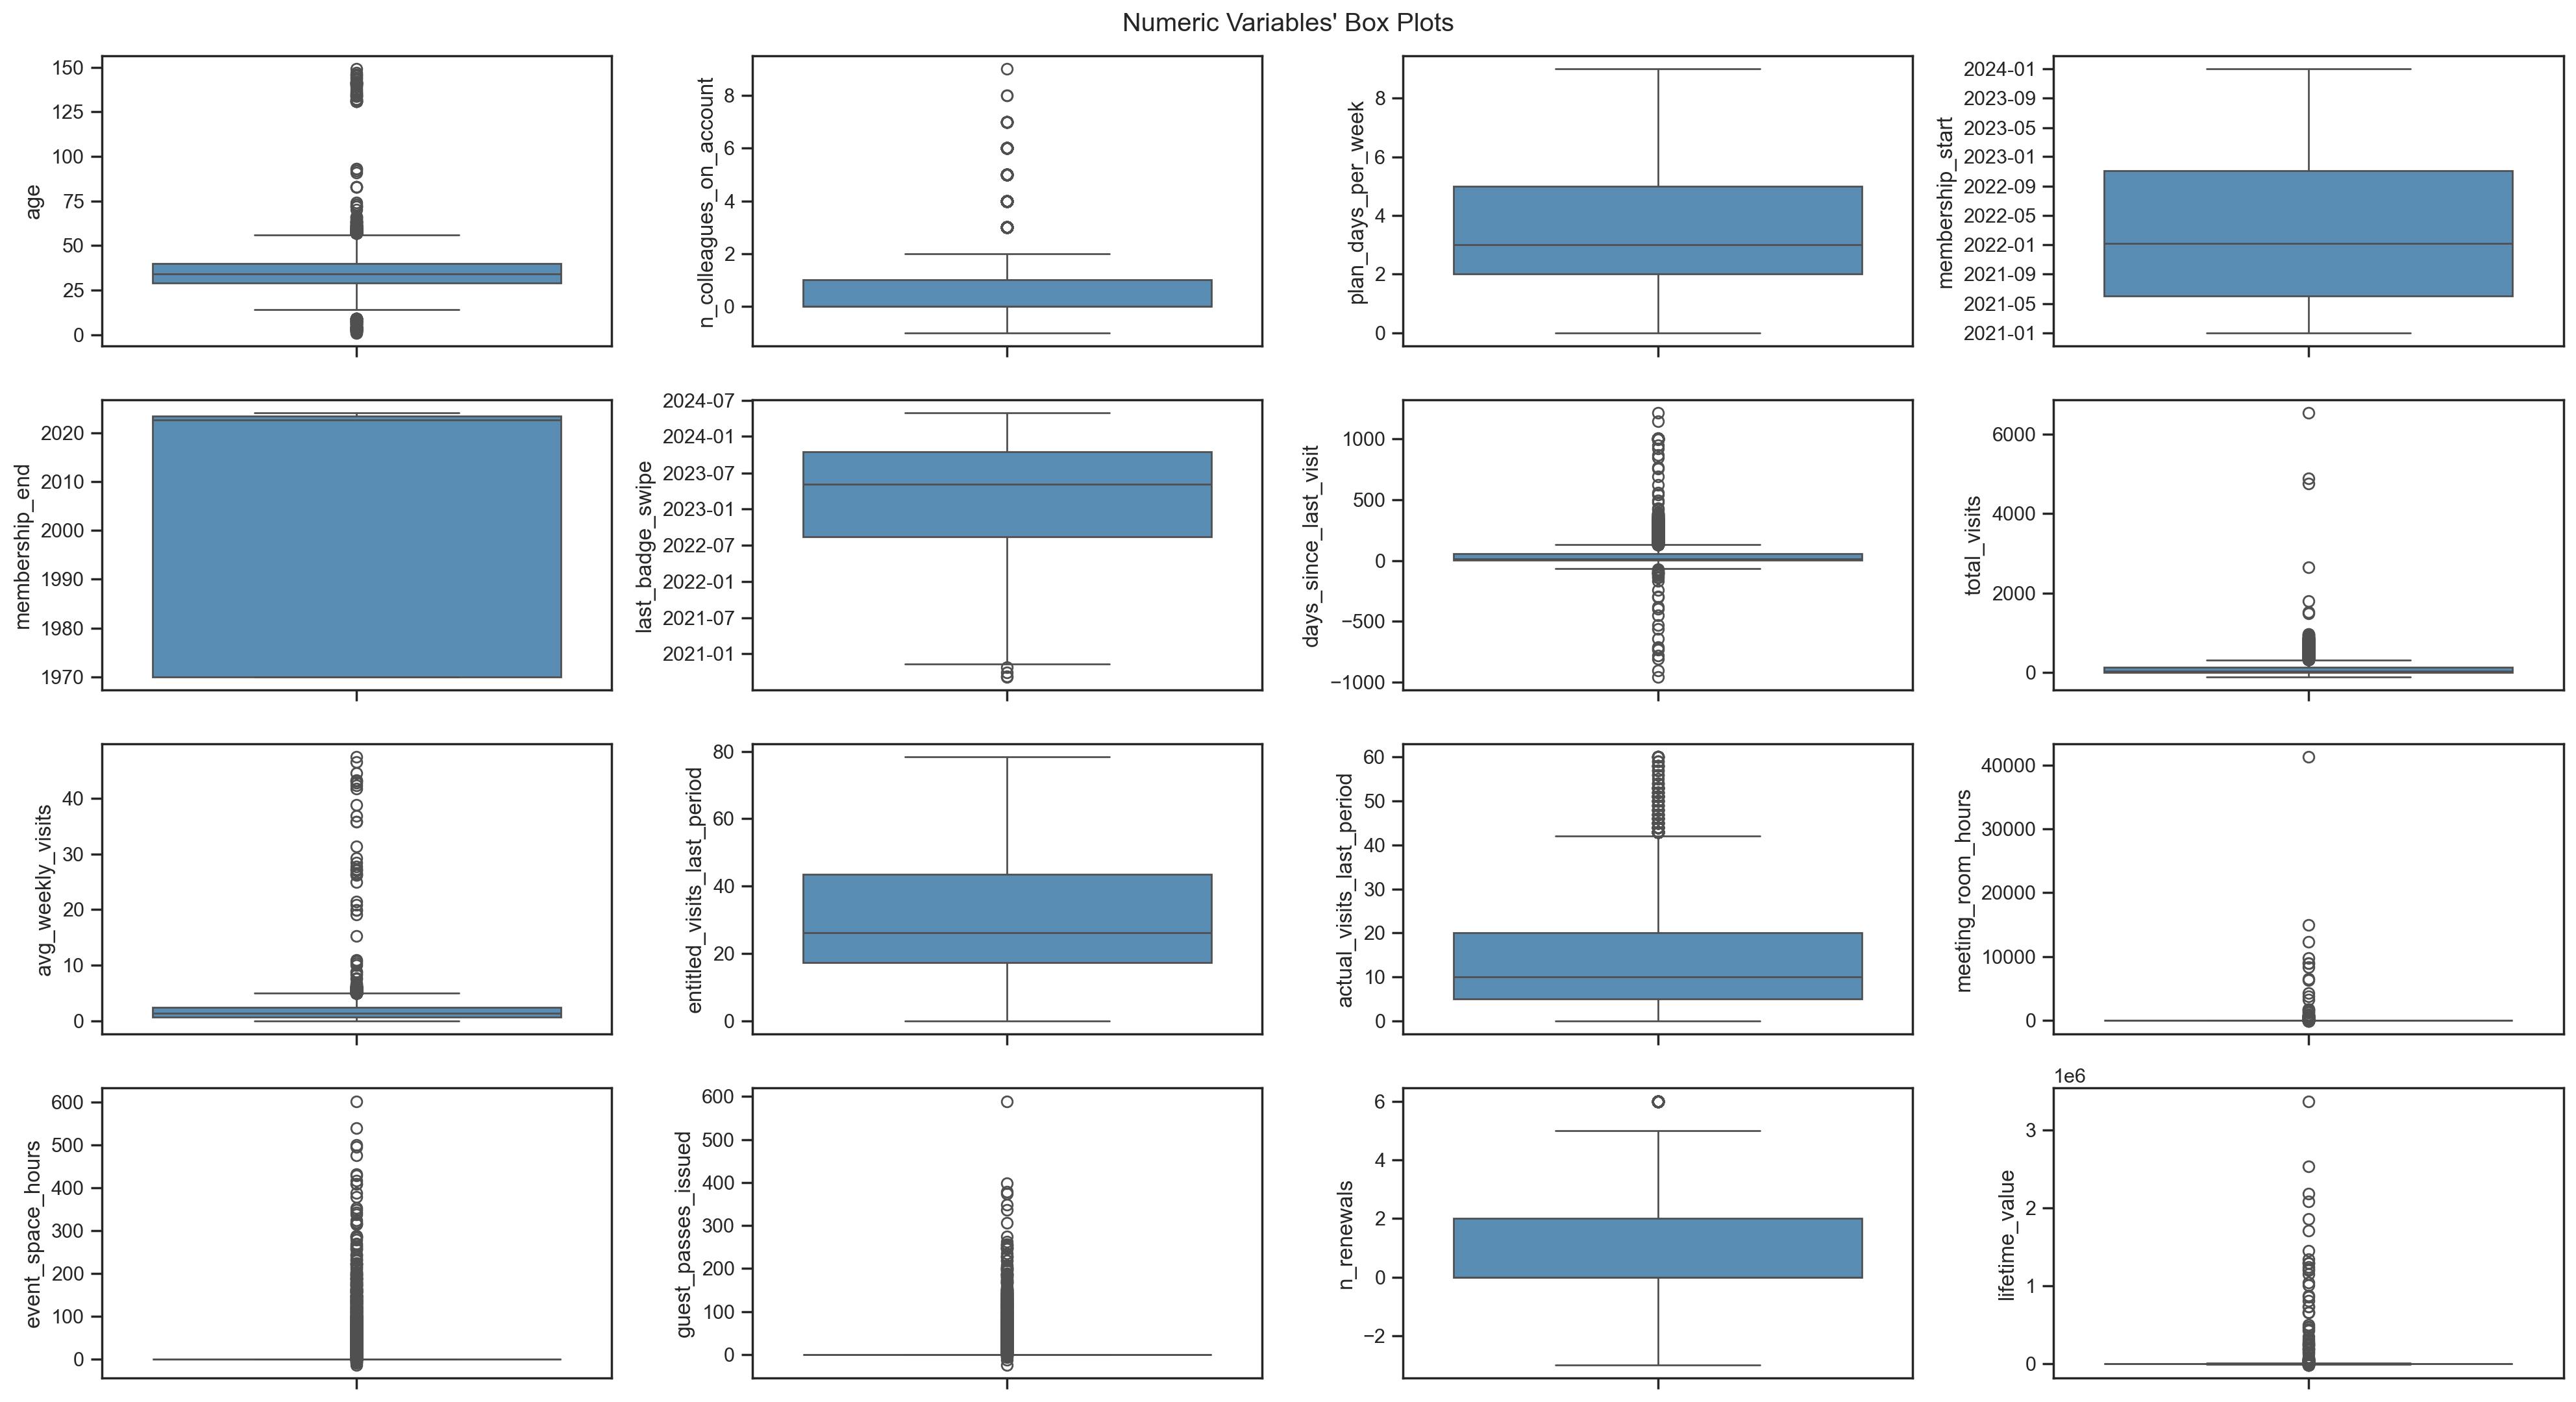

In [18]:
# All Numeric Variables' Box Plots in one figure

# Prepare figure. Create individual axes where each box plot will be placed
fig, axes = plt.subplots(4, ceil(len(metric_features) / 4), figsize=(20, 11))

# Plot data
# Iterate across axes objects and associate each box plot (hint: use the ax argument):
for ax, feat in zip(axes.flatten(), metric_features): # Notice the zip() function and flatten() method
    sns.boxplot(y=df_nodups[feat], color=MAIN_COLOR, ax=ax)
    
# Layout
# Add a centered title to the figure:
title = "Numeric Variables' Box Plots"

plt.suptitle(title)
plt.tight_layout()

plt.show()

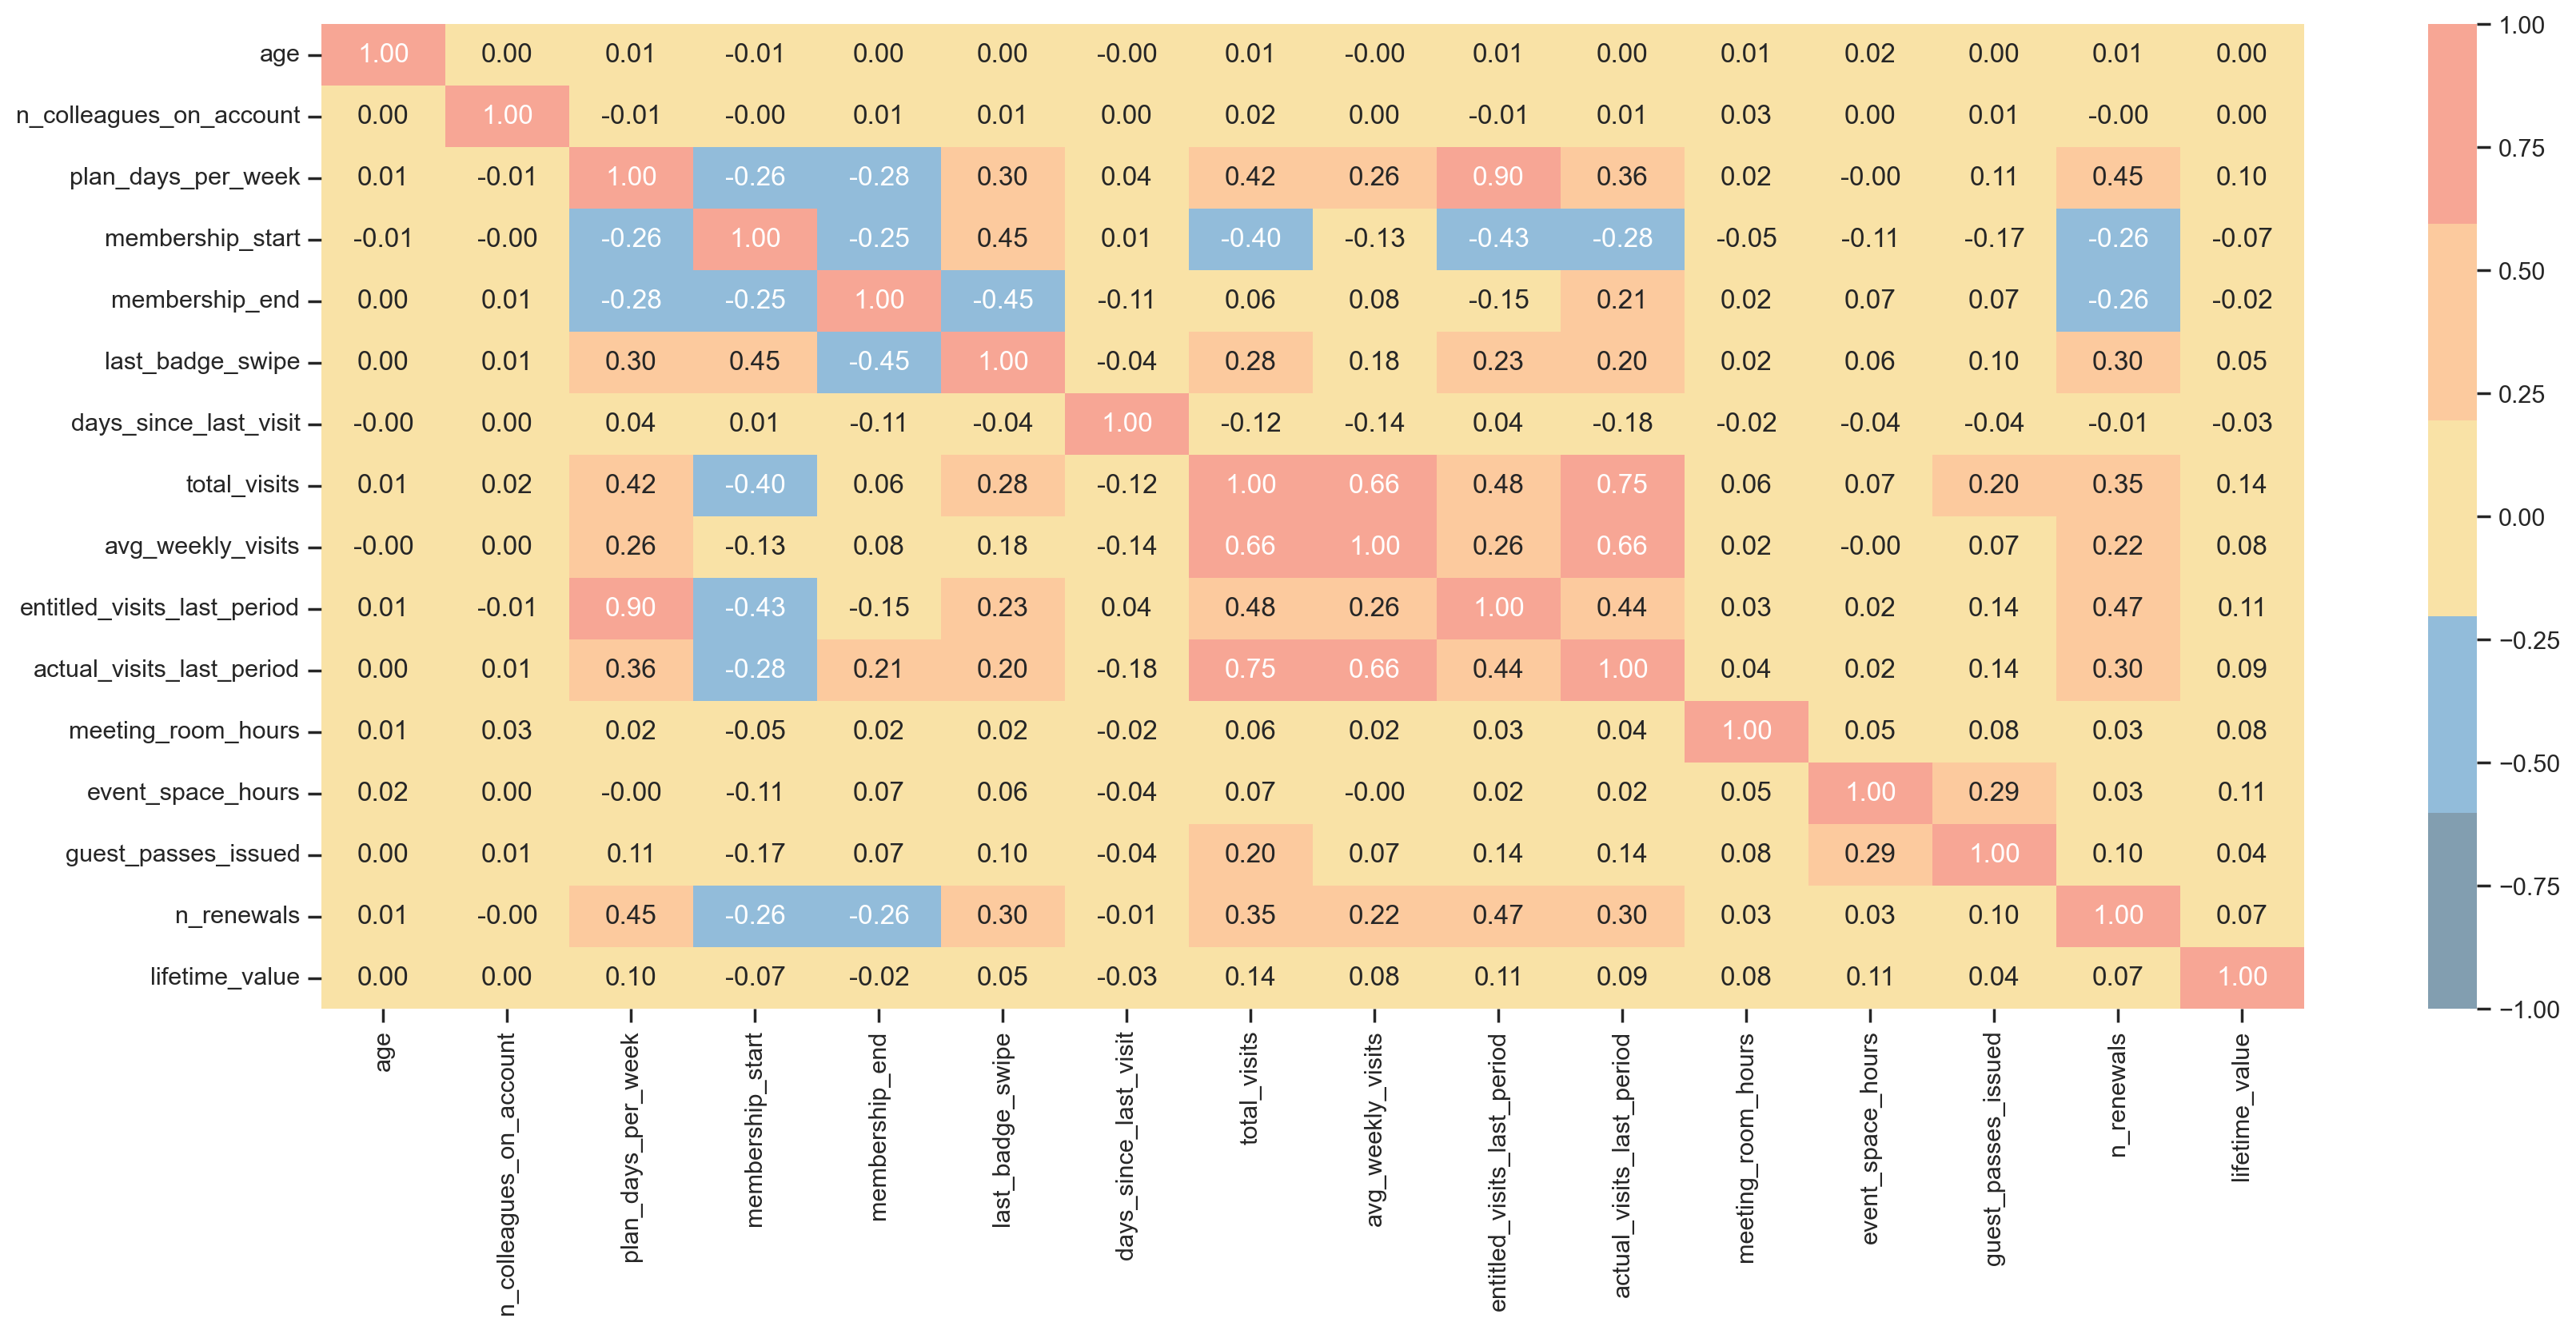

In [19]:
corr = df_nodups[metric_features].corr(method="pearson")

fig = plt.figure(figsize=(20, 8))

sns.heatmap(data=corr, annot=True, cmap=colors, vmin=-1, vmax=1, center=0, fmt=".2f", alpha=0.6)

plt.show()

# Improve
    # Round
    # Lower or upper triangle only
    # Mask values 
    # Divergent color map

- `entitled_visits_last_period` and `plan_days_per_week` have a correlation of 0.90
- `actual_last_visits` and `total_visits` have a 0.75 correlation
- `avg_weekly_visits` has a 0.66 correlation with `actual_visits_last_period` and `total_visits`
- There are some other correlations worth exploring (|p| between 0.30 and 0.50)

# Visualizations for non metric variables

- Categorical features visualizations
- Compare categorical variables with continuous variables

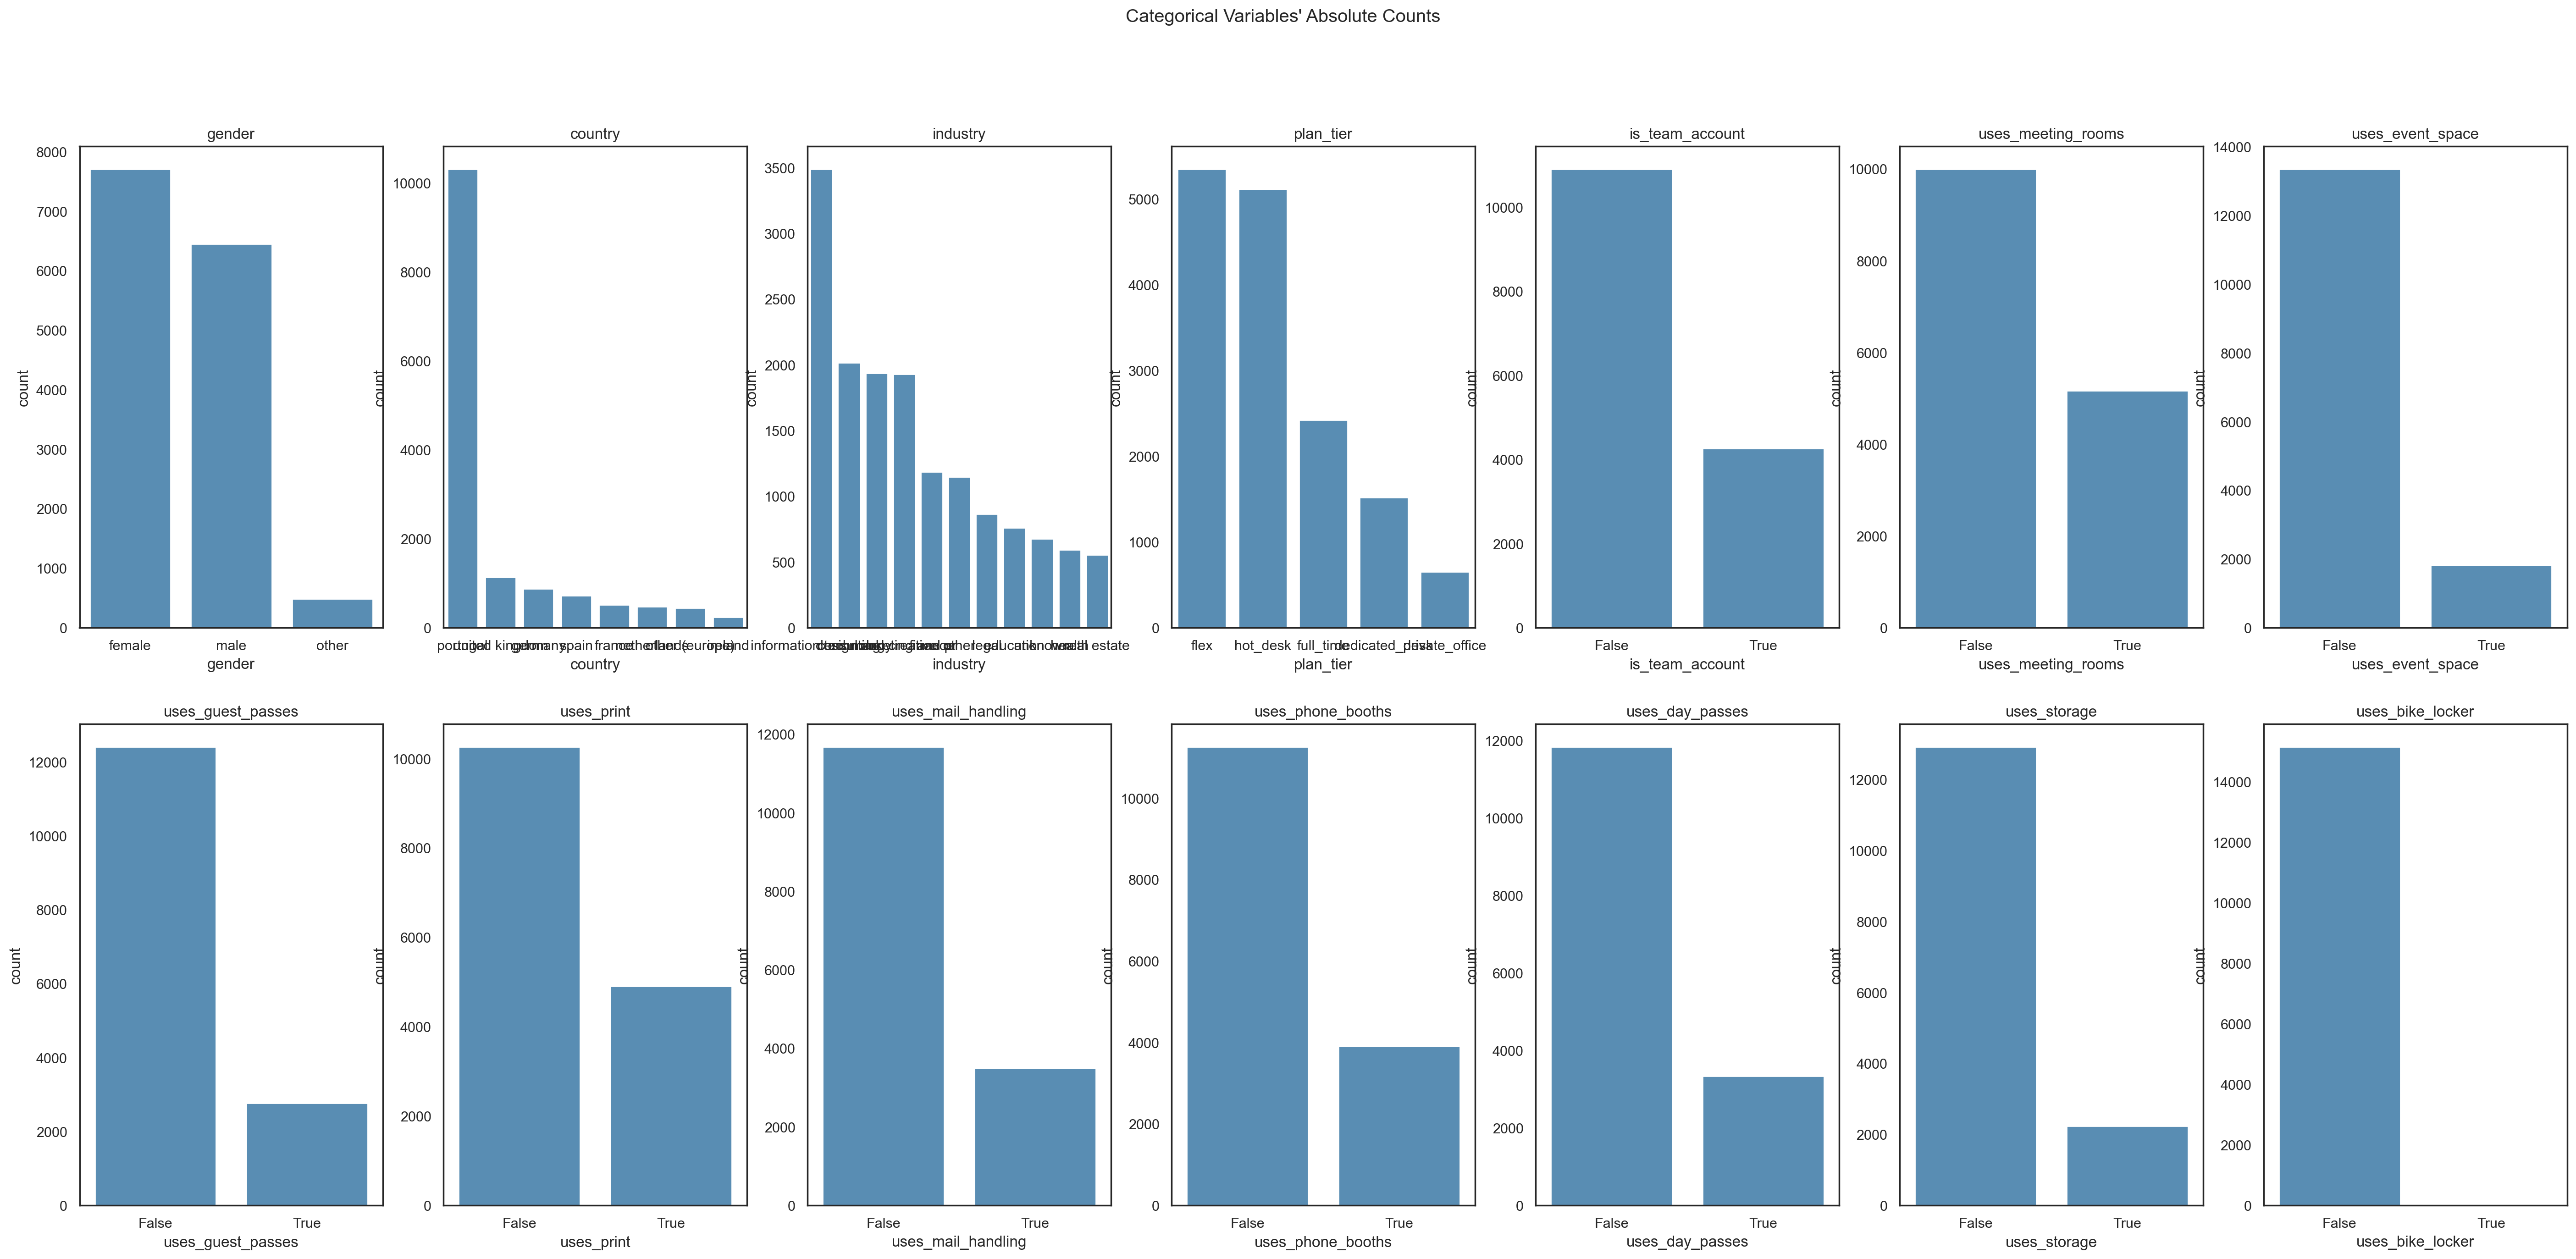

In [20]:
sns.set(style="white")

fig, axes = plt.subplots(
    2, 
    ceil(len(non_metric_features) / 2), 
    figsize=(35, 15)
    )

for ax, feat in zip(axes.flatten(), non_metric_features):
    # use df_deps
    sns.countplot(x=df_nodups[feat], ax=ax, 
                  order=df_nodups[feat].value_counts().index,
                  color=MAIN_COLOR) 
    ax.set_title(feat)


plt.suptitle("Categorical Variables' Absolute Counts")
plt.show()

# plt.savefig(os.path.join('..', 'figures', 'eda', 'categorical_variables_counts.png'), dpi=200)

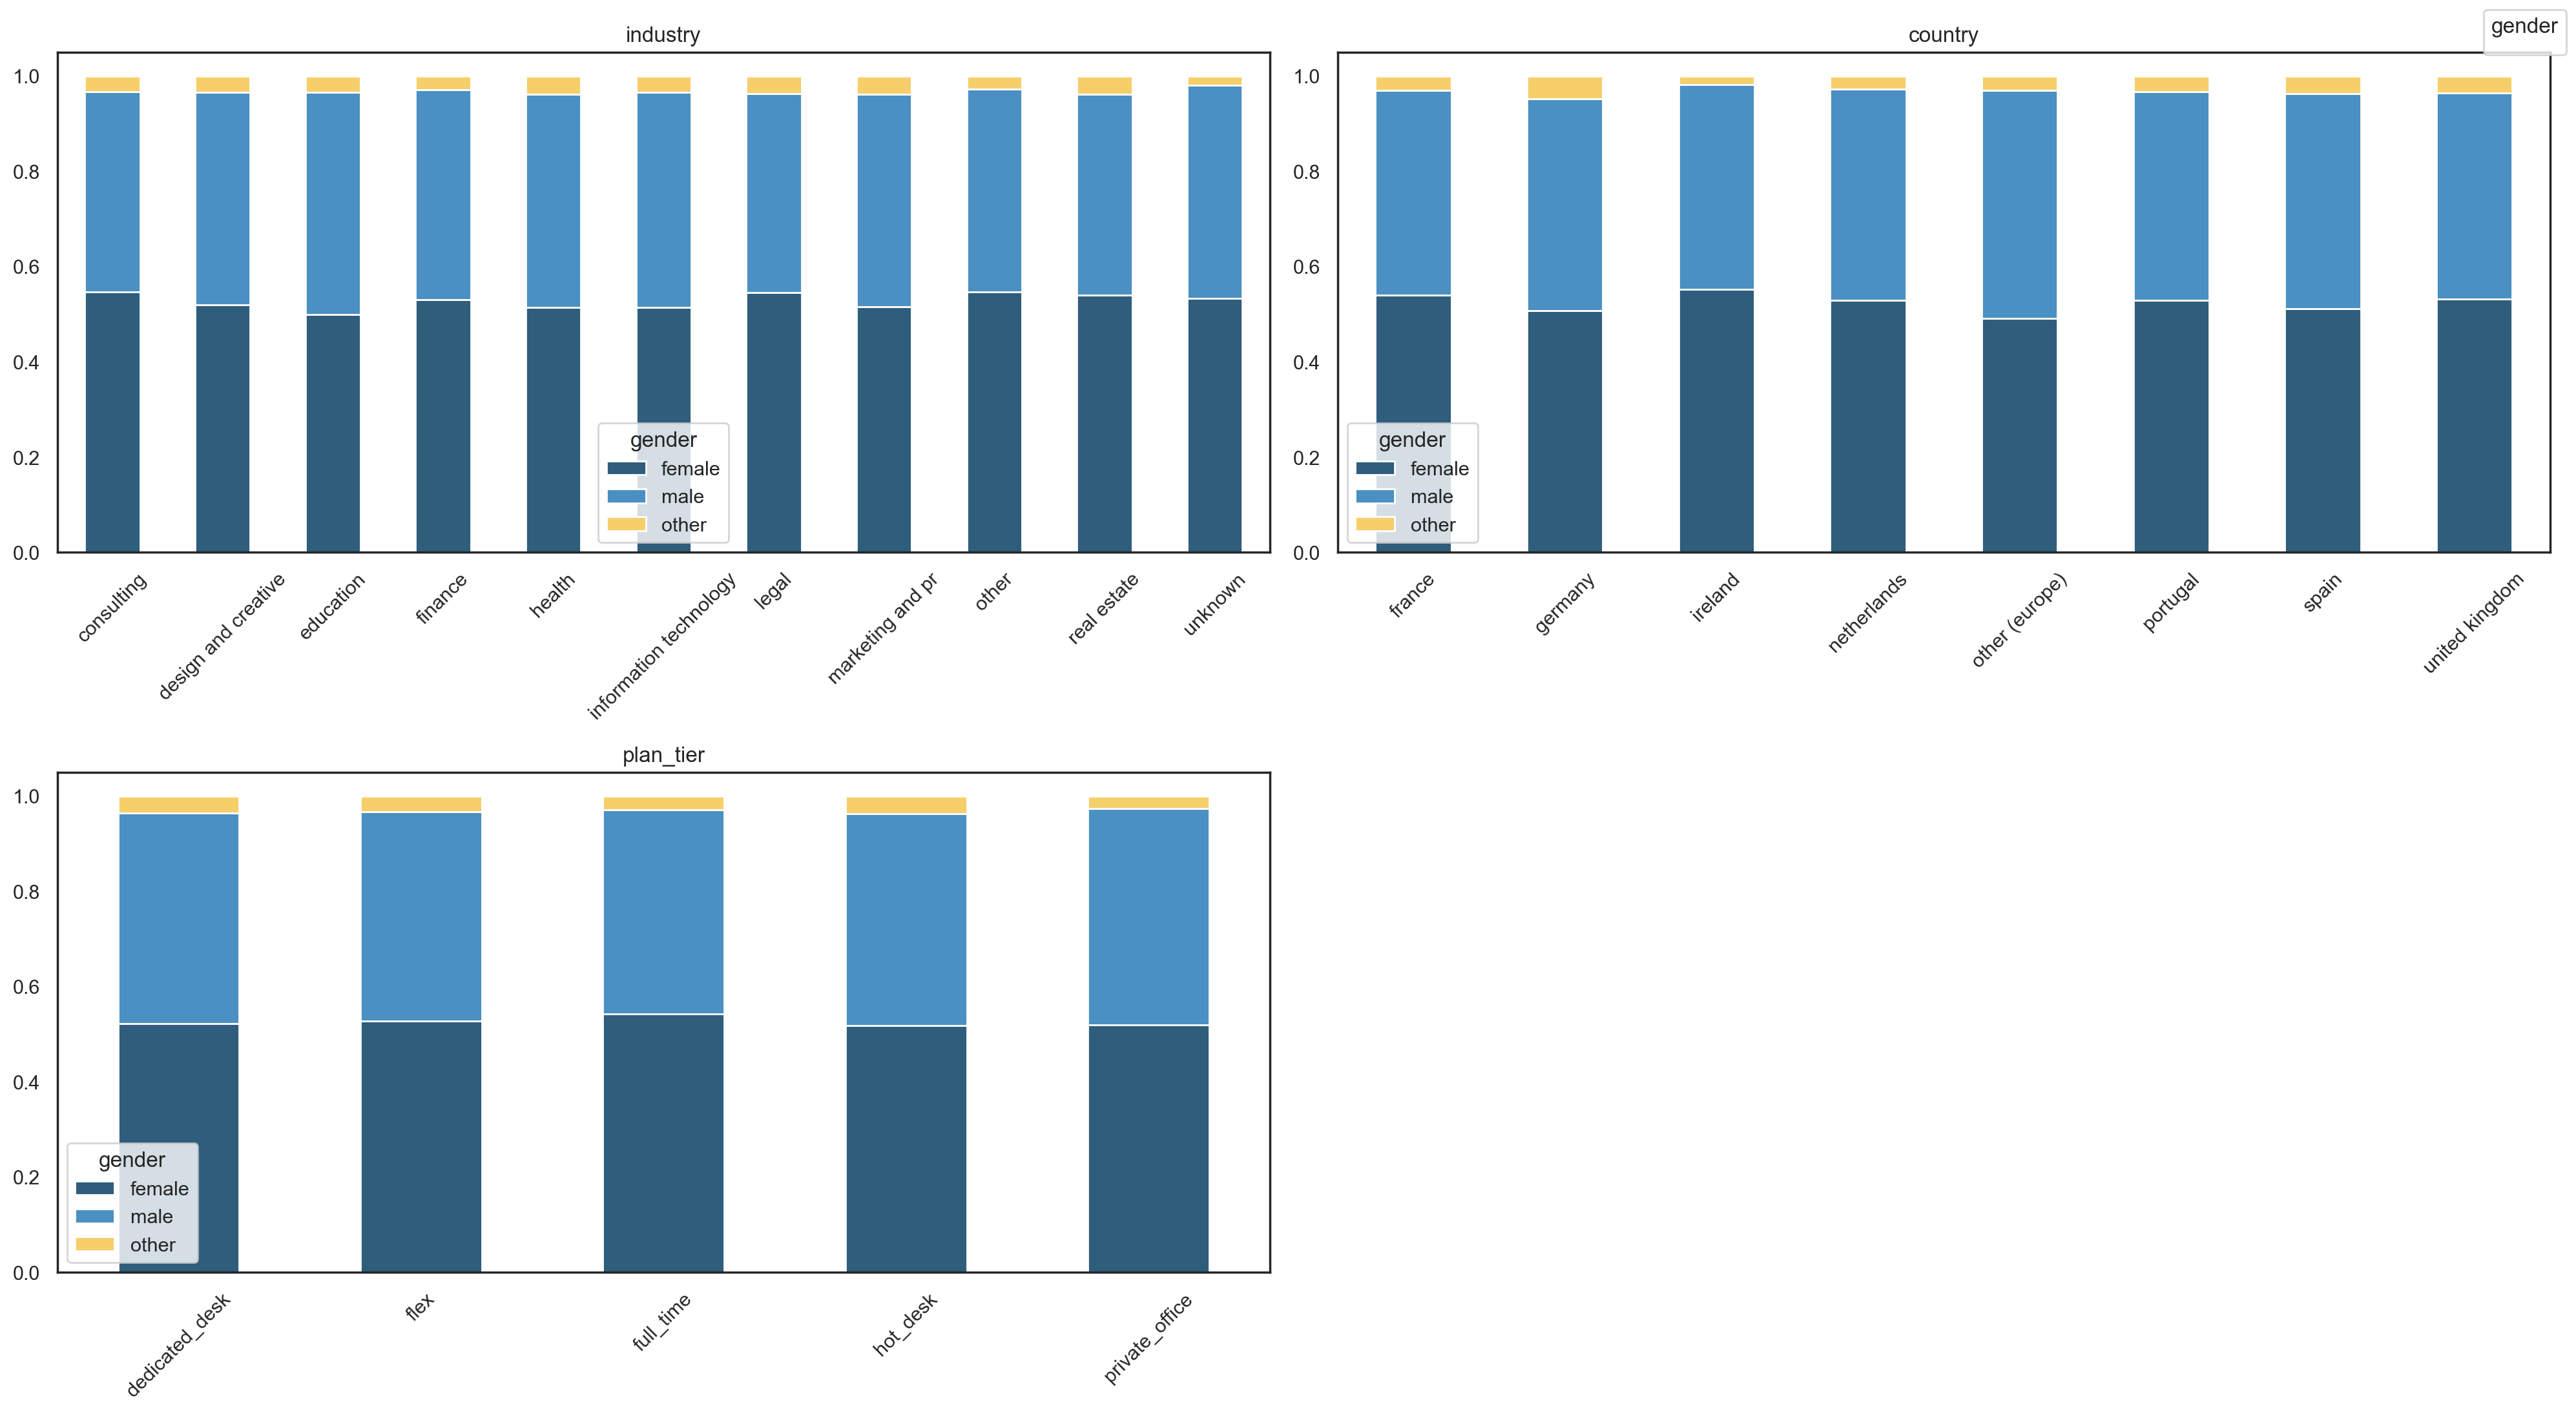

In [21]:
target = "gender" 
object_features = ['industry', 'country', 'plan_tier']

n_rows = 2
n_cols = ceil(len(object_features) / n_rows)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 11))

for ax, feat in zip(axes.flatten(), object_features):
    ct = pd.crosstab(df_nodups[feat], df_nodups[target], normalize="index")
    ct.plot(kind="bar", stacked=True, color= colors, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

# hide unused axes
for ax in axes.flatten()[len(object_features):]:
    ax.set_visible(False)

# single legend for the whole figure
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, title=target, loc="upper right")

plt.tight_layout()
plt.show()


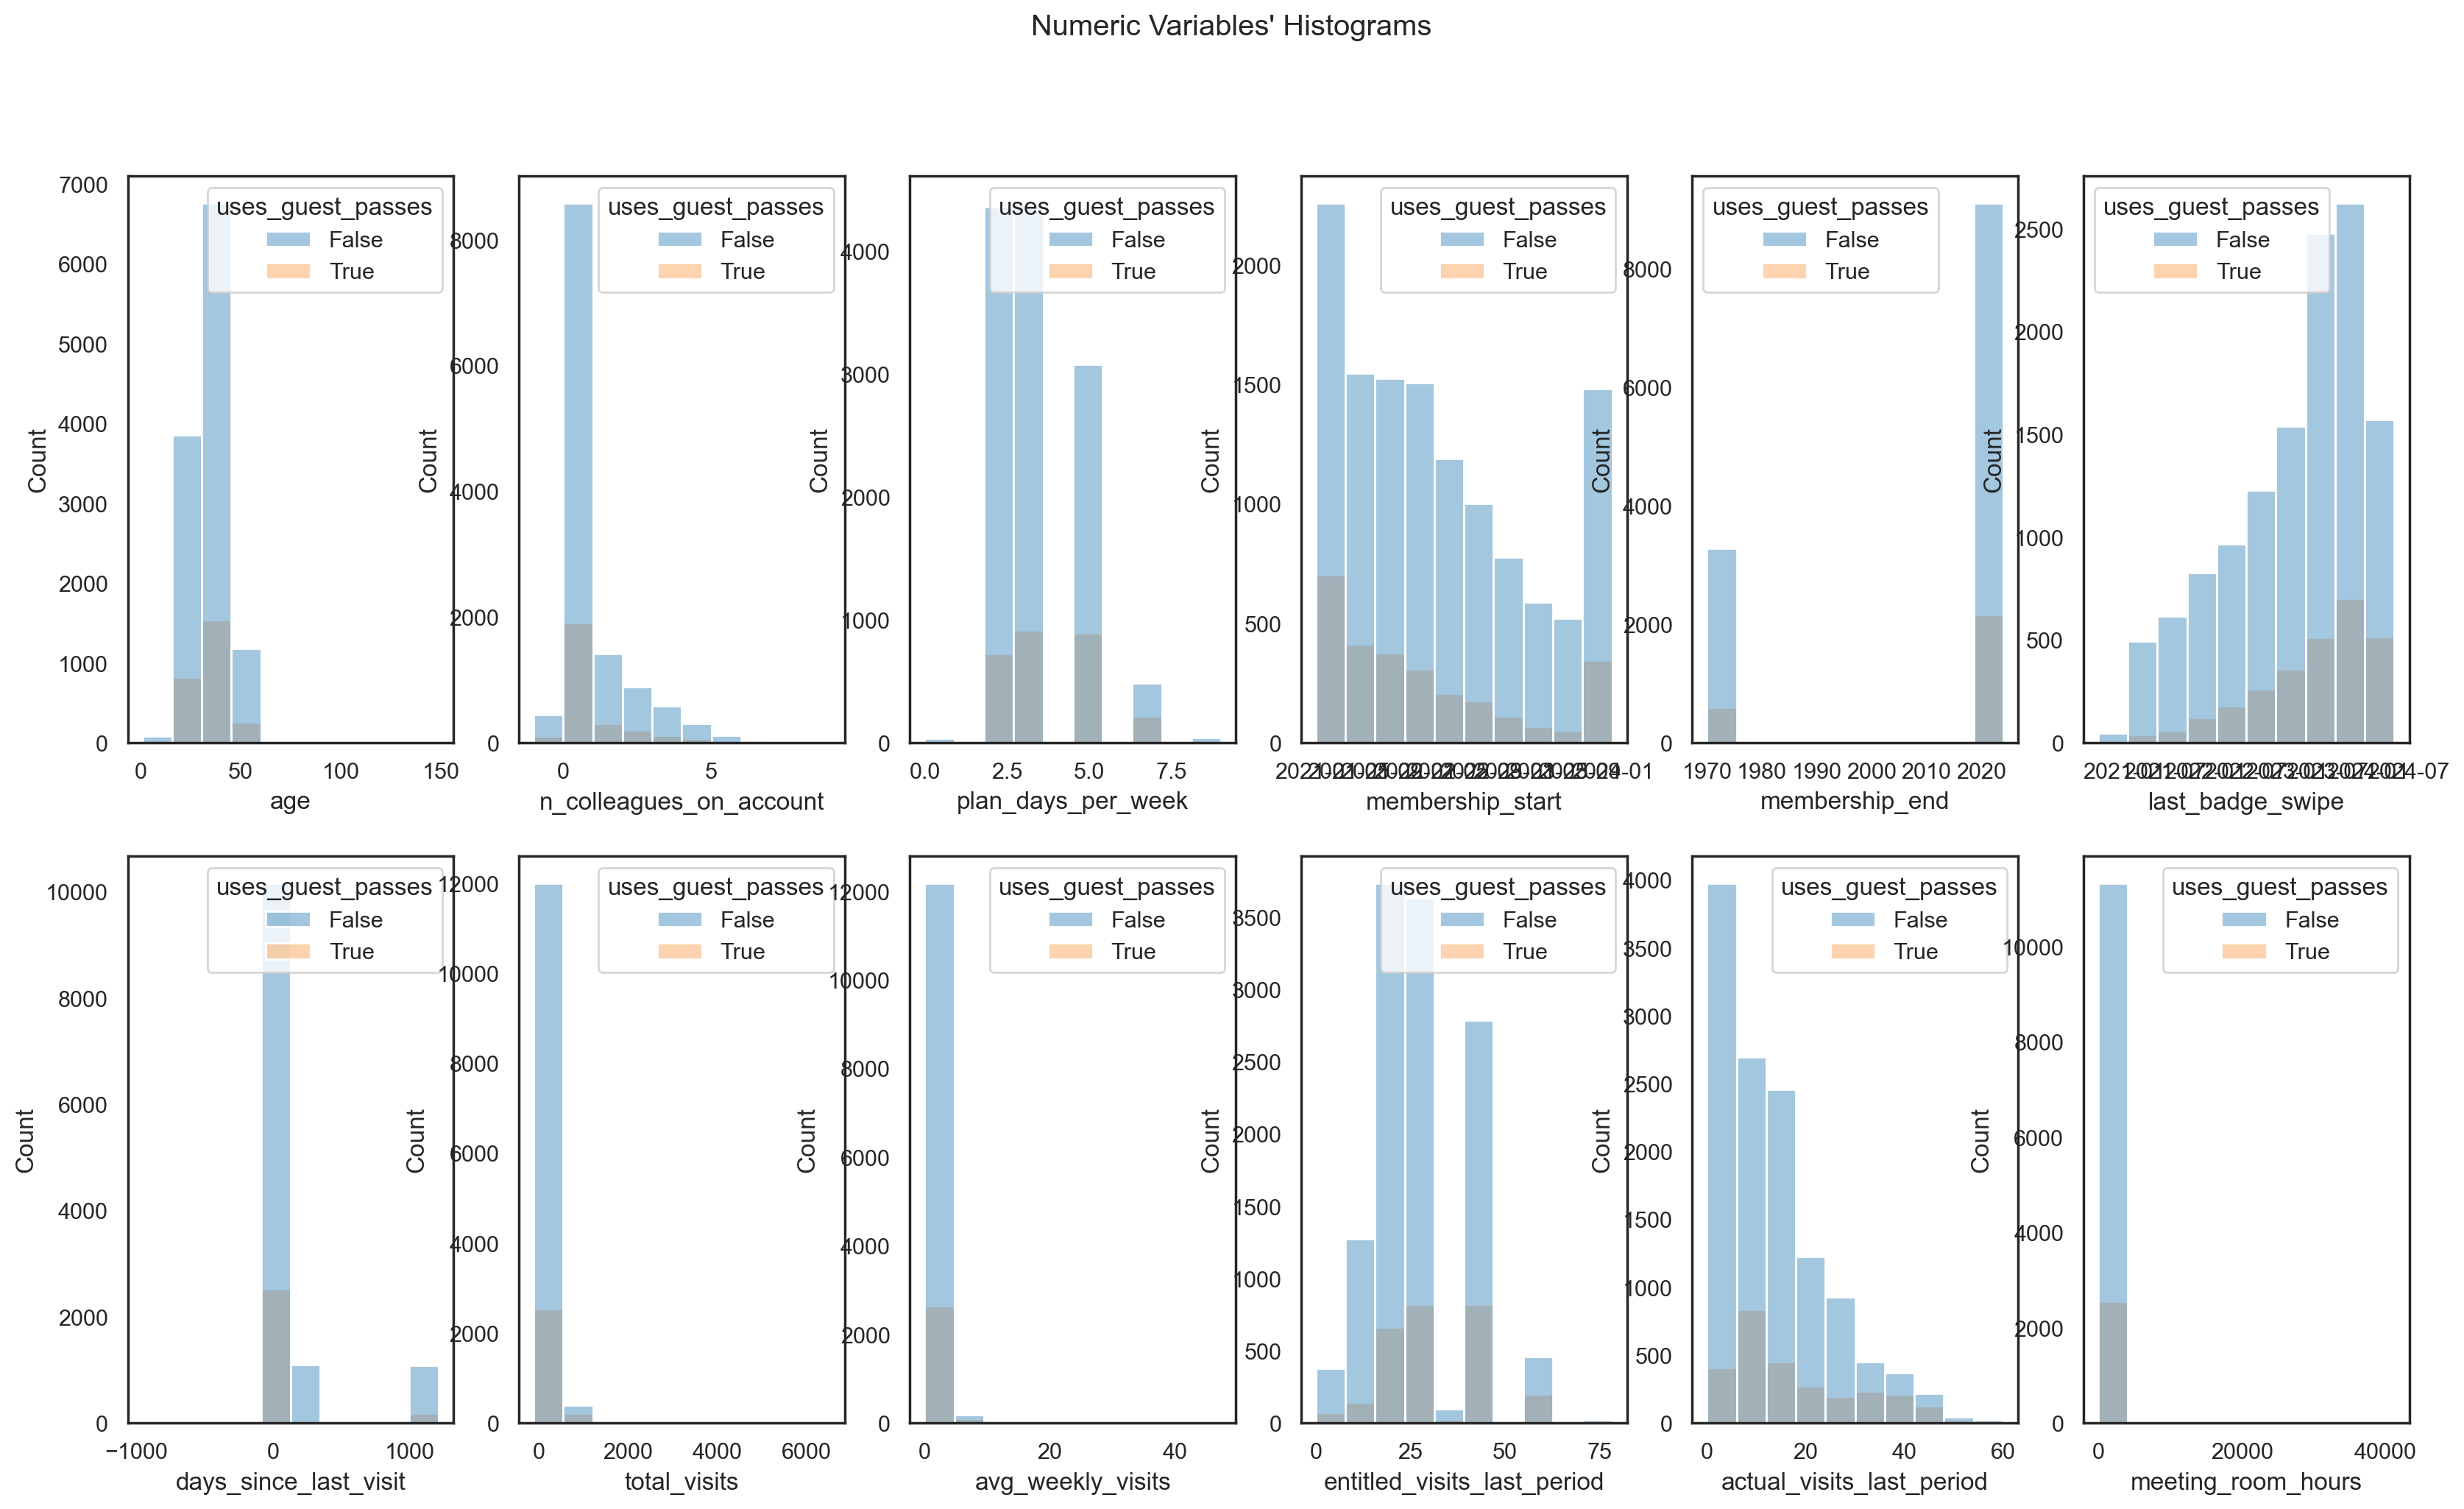

<Figure size 640x480 with 0 Axes>

In [22]:
sns.set_theme(style="white")

sp_rows = 2
sp_cols = 6

fig, axes = plt.subplots(sp_rows, sp_cols, figsize=(20, 11))

# one color per hue level (is_team_account has 2 values)
palette = {False: "#4A90C2", True: "#FAA85E"}

for ax, feat in zip(axes.flatten(), metric_features):
    sns.histplot(df_nodups, x=feat, ax=ax, bins=10, hue="uses_guest_passes", palette=palette)

plt.suptitle("Numeric Variables' Histograms")
plt.show()

plt.suptitle(title)

plt.show()